First Five Records:
                                     Patient_Problem  \
0  Constant fatigue and muscle weakness, struggli...   
1  Frequent severe migraines, sensitivity to ligh...   
2  Sudden weight gain and feeling cold, especiall...   
3  High fever, sore throat, and swollen lymph nod...   
4  Excessive thirst and frequent urination, dry m...   

                    Disease                                       Prescription  
0  Chronic Fatigue Syndrome  Cognitive behavioral therapy, graded exercise ...  
1        Migraine with Aura  Prescription triptans, avoid triggers like bri...  
2            Hypothyroidism  Levothyroxine to regulate thyroid hormone levels.  
3             Mononucleosis            Rest and hydration, ibuprofen for pain.  
4         Diabetes Mellitus             Insulin therapy and lifestyle changes.  

Dataset Shape: (407, 3)

Columns:
Index(['Patient_Problem', 'Disease', 'Prescription'], dtype='object')

Number of Disease Classes: 178


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Model Summary


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        78,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 178)            │        11,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,802 (385.95 KB)

 Trainable params: 98,802 (385.95 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.0269 - loss: 5.1763 - val_accuracy: 0.0462 - val_loss: 5.1721
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.0654 - loss: 5.1177 - val_accuracy: 0.0308 - val_loss: 5.1620
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.0731 - loss: 5.0298 - val_accuracy: 0.0308 - val_loss: 5.1528
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.0500 - loss: 4.8529 - val_accuracy: 0.0154 - val_loss: 5.1888
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0462 - loss: 4.5881 - val_accuracy: 0.0308 - val_loss: 5.3860
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0692 - loss: 4.3644 - val_accuracy: 0.0308 - val_loss: 5.5356
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0846 - loss: 4.1775 - val_accuracy: 0.0154 - val_loss: 5.5711
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.1038 - loss: 3.9811 - val_accuracy: 0.0308 - v

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_

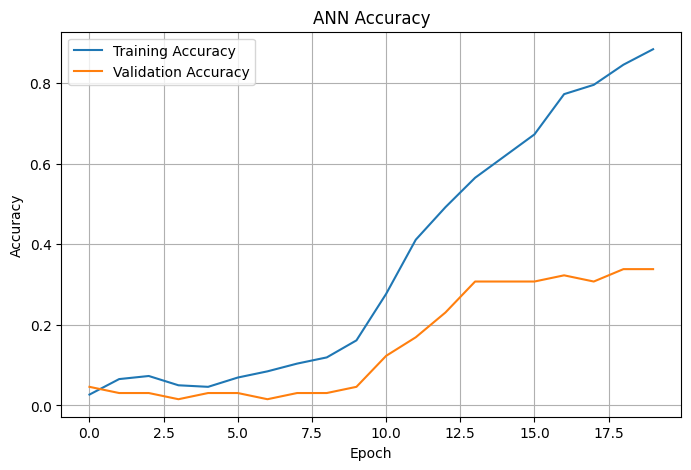

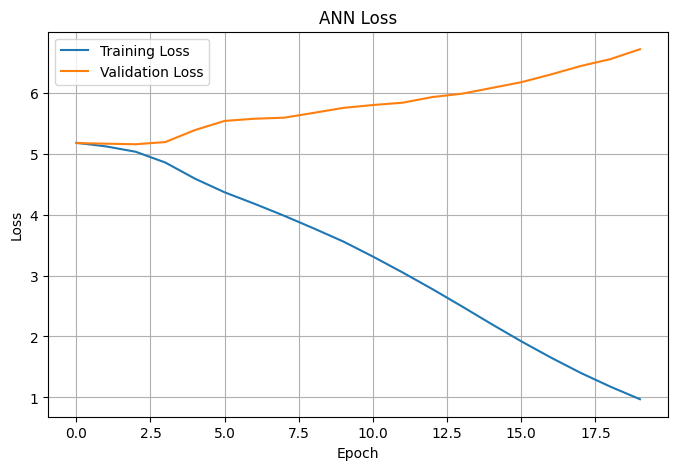

In [ ]:
# ==========================================
# ANN for Disease Classification
# ==========================================

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import plot_model

# ==========================================
# Load Dataset
# ==========================================

data = pd.read_csv("/content/medical_data.csv")

print("First Five Records:")
print(data.head())

print("\nDataset Shape:", data.shape)

print("\nColumns:")
print(data.columns)

# ==========================================
# Input and Output
# ==========================================

X = data["Patient_Problem"]
y = data["Disease"]

# ==========================================
# Convert Text into Numerical Features
# ==========================================

tfidf = TfidfVectorizer(max_features=1000)

X = tfidf.fit_transform(X).toarray()

# ==========================================
# Encode Disease Labels
# ==========================================

encoder = LabelEncoder()

y = encoder.fit_transform(y)

print("\nNumber of Disease Classes:", len(np.unique(y)))

# ==========================================
# Split Dataset
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ==========================================
# Build ANN Model
# ==========================================

model = Sequential()

# Input Layer
model.add(Dense(128,
                activation='relu',
                input_shape=(X_train.shape[1],)))

# Hidden Layer
model.add(Dense(64,
                activation='relu'))

# Output Layer
model.add(Dense(len(np.unique(y)),
                activation='softmax'))

# ==========================================
# Compile Model
# ==========================================

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# ==========================================
# Model Summary
# ==========================================

print("\nModel Summary")
model.summary()

# ==========================================
# Train Model
# ==========================================

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=16,
    verbose=1
)

# ==========================================
# Evaluate Model
# ==========================================

loss, accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss :", loss)
print("Test Accuracy :", accuracy)

# ==========================================
# Predictions
# ==========================================

predictions = model.predict(X_test)

predicted_classes = np.argmax(predictions, axis=1)

# ==========================================
# Accuracy
# ==========================================

acc = accuracy_score(y_test, predicted_classes)

print("\nAccuracy Score :", acc)

# ==========================================
# Classification Report
# ==========================================

print("\nClassification Report")

print(classification_report(
    y_test,
    predicted_classes
))

# ==========================================
# Confusion Matrix
# ==========================================

cm = confusion_matrix(y_test, predicted_classes)

print("\nConfusion Matrix")

print(cm)

# ==========================================
# Predict Diseases for Sample Patients
# ==========================================

sample_patients = [
    "High fever and headache",
    "Chest pain with shortness of breath",
    "Sneezing and runny nose",
    "Stomach pain and vomiting"
]

sample_vectors = tfidf.transform(sample_patients).toarray()

pred = model.predict(sample_vectors)

predicted_labels = encoder.inverse_transform(np.argmax(pred, axis=1))

print("\nSample Predictions")

for patient, disease in zip(sample_patients, predicted_labels):
    print(f"Patient Problem : {patient}")
    print(f"Predicted Disease : {disease}")
    print("----------------------------------")

# ==========================================
# Plot Accuracy
# ==========================================

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("ANN Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

# ==========================================
# Plot Loss
# ==========================================

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("ANN Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

# New Section

### Handle Imbalanced Dataset

With 178 unique disease classes, it's highly probable that the dataset is imbalanced (some diseases have many samples, while others have very few). Training an ANN on an imbalanced dataset can lead to a model that performs well on majority classes but poorly on minority classes. To mitigate this, we will use the Synthetic Minority Over-sampling Technique (SMOTE) to create synthetic samples for the minority classes in the training data, thereby balancing the class distribution.

In [ ]:
# Install imbalanced-learn if not already installed
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE

print("Original training data shape: ", X_train.shape, y_train.shape)

smt = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smt.fit_resample(X_train, y_train)

print("Resampled training data shape: ", X_train_resampled.shape, y_train_resampled.shape)

# Update X_train and y_train to use the resampled data for model training
X_train = X_train_resampled
y_train = y_train_resampled

Original training data shape:  (325, 616) (325,)


ValueError: Expected n_neighbors <= n_samples_fit, but n_neighbors = 6, n_samples_fit = 1, n_samples = 1